# Para quem mandar a campanha?

**Para quem compra por causa dela, e não para quem compraria de qualquer jeito.** Um modelo de propensão comum
escolhe quem mais responde. O que paga a campanha é quem muda de comportamento por recebê-la, e isso é outra
pergunta: a do *uplift*, o efeito causal da campanha em cada tipo de cliente.

Este notebook conta a história com as tabelas. A base é o experimento de e-mail de Kevin Hillstrom (MineThatData,
2008): 64 mil clientes sorteados entre três grupos (e-mail da linha masculina, e-mail da linha feminina, nenhum
e-mail), com visita ao site, compra e gasto nas duas semanas seguintes.

Como ler: as peças centrais do método são refeitas ao vivo aqui, chamando o pacote `uplift_campanha`. As tabelas
completas (bootstrap, placebo, repetições) vêm de `reports/resultados.json`, gerado por `scripts/rodar_analise.py`,
e o notebook confere que as duas coisas batem.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from matplotlib.ticker import FuncFormatter

from uplift_campanha import analise, curvas, dados, experimento, uplift
from uplift_campanha.estilo import APAGADO, AZUL, ESTILO, LARANJA, nova_figura

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:.3f}")

resultados = json.loads(Path("reports/resultados.json").read_text(encoding="utf-8"))
tabela = dados.carregar()
print(f"{len(tabela):,} clientes".replace(",", "."))
tabela[["grupo", "recencia", "historico", "comprou_masculino", "comprou_feminino", "cliente_novo", "visita", "conversao", "gasto"]].head()

64.000 clientes


,grupo,recencia,historico,comprou_masculino,comprou_feminino,cliente_novo,visita,conversao,gasto
0,E-mail feminino,10,142.440,1,0,0,0,0,0.000
1,Sem e-mail,6,329.080,1,1,1,0,0,0.000
2,E-mail feminino,7,180.650,0,1,1,0,0,0.000
3,E-mail masculino,9,675.830,1,0,1,0,0,0.000
4,E-mail feminino,2,45.340,1,0,0,0,0,0.000


## 1. O sorteio foi bem feito?

Num experimento aleatorizado, a diferença entre os grupos é o efeito da campanha, desde que o sorteio tenha
funcionado. Duas checagens: os três grupos têm o mesmo tamanho (teste qui-quadrado contra a divisão igual) e os
atributos anteriores ao envio estão equilibrados (diferença padronizada de médias; a regra de bolso aceita até 0,1).

In [2]:
base = analise.resumo_da_base(tabela)
print("Clientes por grupo:", base["por_grupo"])
print(f"Teste da divisão em três partes iguais: p = {base['teste_da_divisao']['p']:.2f}")

equilibrio = analise.equilibrio(tabela)
print(f"Maior diferença padronizada, em módulo: {np.abs(equilibrio.to_numpy()).max():.3f}")
equilibrio

Clientes por grupo: {'E-mail feminino': 21387, 'E-mail masculino': 21307, 'Sem e-mail': 21306}
Teste da divisão em três partes iguais: p = 0.90


Maior diferença padronizada, em módulo: 0.014


,E-mail feminino,E-mail masculino
Meses desde a última compra,0.005,0.007
Gasto no último ano (log),0.006,-0.001
Comprou linha masculina,-0.009,-0.005
Comprou linha feminina,0.005,0.008
Cliente novo (12 meses),0.003,-0.001
Região urbana,-0.002,0.002
Região suburbana,-0.001,-0.012
Região rural,0.004,0.014
Comprou por telefone,0.009,-0.008
Comprou pela web,-0.005,0.011


Os grupos são do mesmo tamanho e nenhum atributo difere mais que 0,014 desvio padrão. O sorteio funcionou: dá para
ler diferença entre grupos como efeito do e-mail, sem modelo nenhum.

## 2. O efeito médio de cada e-mail

Antes de perguntar *para quem* o e-mail funciona, a pergunta é *se* funciona e quanto.

In [3]:
efeitos = analise.efeitos_medios(tabela)
em_pontos = efeitos[["media_controles", "media_tratados", "efeito", "ic_inferior", "ic_superior"]].copy()
taxas = [i for i in em_pontos.index if i[1] != "gasto"]
em_pontos.loc[taxas] = em_pontos.loc[taxas] * 100  # visita e compra em pontos percentuais; gasto em dólares por cliente
em_pontos["efeito_relativo"] = efeitos["efeito_relativo"]
em_pontos["p"] = efeitos["p"]
em_pontos.round(3)

media_controles  media_tratados  efeito  ic_inferior  ic_superior  efeito_relativo     p
campanha         desfecho                                                                                           
E-mail feminino  visita              10.617          15.140   4.523        3.889        5.157            0.426 0.000
                 conversao            0.573           0.884   0.311        0.150        0.472            0.543 0.000
                 gasto                0.653           1.077   0.424        0.169        0.680            0.650 0.001
E-mail masculino visita              10.617          18.276   7.659        6.995        8.323            0.721 0.000
                 conversao            0.573           1.253   0.681        0.500        0.861            1.188 0.000
                 gasto                0.653           1.423   0.770        0.485        1.055            1.179 0.000

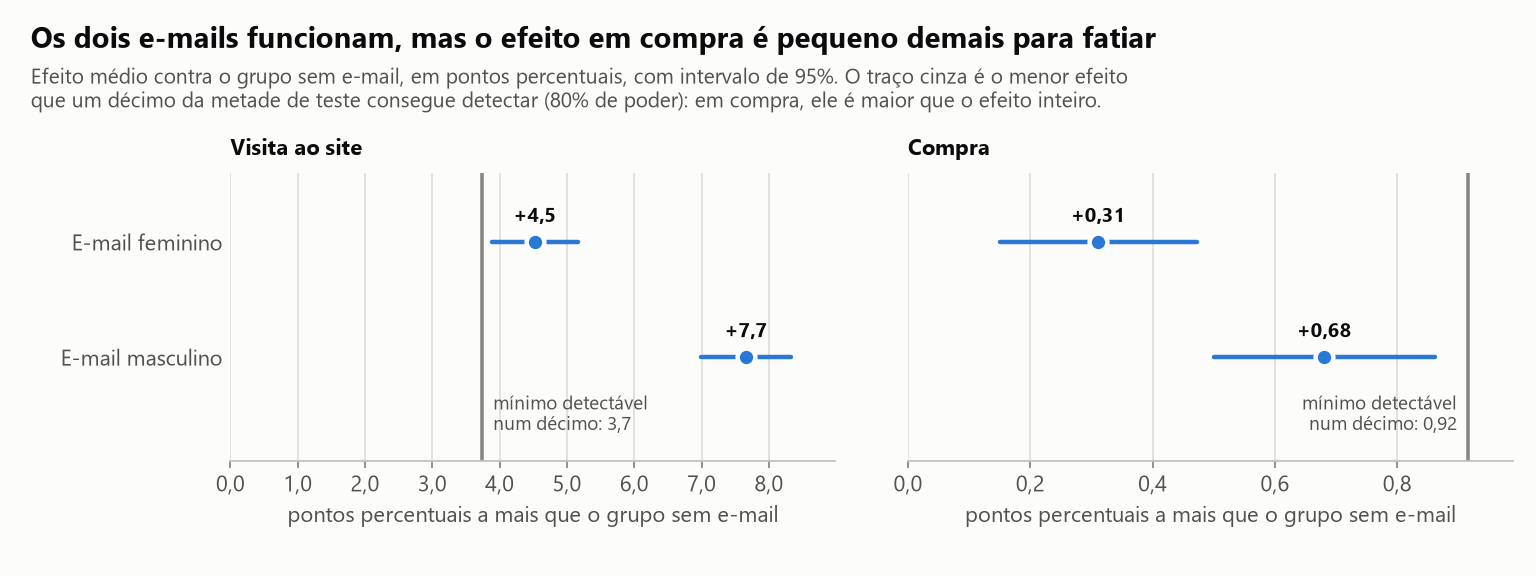

In [4]:
display(Image(filename="reports/figuras/efeito_medio.png", width=820))

Os dois e-mails trazem visitas e compras. Mas olhe a escala: o efeito em compra é de frações de ponto percentual,
mais de dez vezes menor que o efeito em visita. Isso decide o que dá para analisar por fatia da base.

In [5]:
poder = analise.poder_por_recorte(tabela, efeitos)
linhas = []
for desfecho in ("visita", "conversao"):
    for recorte, valores in poder[desfecho]["minimo_detectavel"].items():
        linhas.append({
            "desfecho": desfecho,
            "recorte": recorte,
            "clientes por grupo": valores["clientes_por_grupo"],
            "mínimo detectável (p.p.)": 100 * valores["efeito"],
            "efeito do e-mail feminino (p.p.)": 100 * poder[desfecho]["efeito_medio"]["E-mail feminino"],
            "efeito do e-mail masculino (p.p.)": 100 * poder[desfecho]["efeito_medio"]["E-mail masculino"],
        })
pd.DataFrame(linhas).set_index(["desfecho", "recorte"]).round(2)

clientes por grupo  mínimo detectável (p.p.)  efeito do e-mail feminino (p.p.)  efeito do e-mail masculino (p.p.)
desfecho  recorte                                                                                                                               
visita    experimento inteiro               21306                     0.840                             4.520                              7.660
          metade de teste                   10653                     1.180                             4.520                              7.660
          30% do teste                       3196                     2.160                             4.520                              7.660
          um decil do teste                  1065                     3.740                             4.520                              7.660
conversao experimento inteiro               21306                     0.200                             0.310                              0.680
          metade de teste                   10653                     0.290                             0.310                              0.680
          30% do teste                       3196                     0.530                             0.310                              0.680
          um decil do teste                  1065                     0.920                             0.310                              0.680

Um décimo da metade de teste (cerca de mil clientes por grupo) só detecta, com 80% de poder, um efeito em compra
maior que o efeito inteiro de qualquer um dos e-mails. Por isso **o desfecho principal deste estudo é a visita**; a
compra entra como desfecho secundário, com a incerteza à mostra.

## 3. A régua: curva Qini num caso de resposta conhecida

Ninguém recebe e não recebe o e-mail ao mesmo tempo, então não existe "uplift observado" de um cliente para
comparar com a previsão. O que dá para medir é em grupo: ordenar os clientes pelo escore e, para cada fração do
topo, comparar tratados e controles. Essa é a curva Qini; a área entre ela e a reta do acaso é o coeficiente Qini.

Antes de usar a régua nos dados, ela é conferida onde a resposta é conhecida (os mesmos casos estão em `tests/`):

- efeito verdadeiro 0,5·x, com x uniforme: o escore perfeito tem de dar Qini = 1/24;
- efeito igual para todos: qualquer escore, até um ótimo modelo de resposta, tem de ficar na diagonal (Qini = 0).

Efeito 0,5·x, escore perfeito:  Qini = 0.0420   (teoria: 0.0417)
Efeito 0,5·x, escore invertido: Qini = -0.0420  (teoria: -0.0417)


Efeito constante, escore = x:   Qini = 0.0007   (teoria: 0)


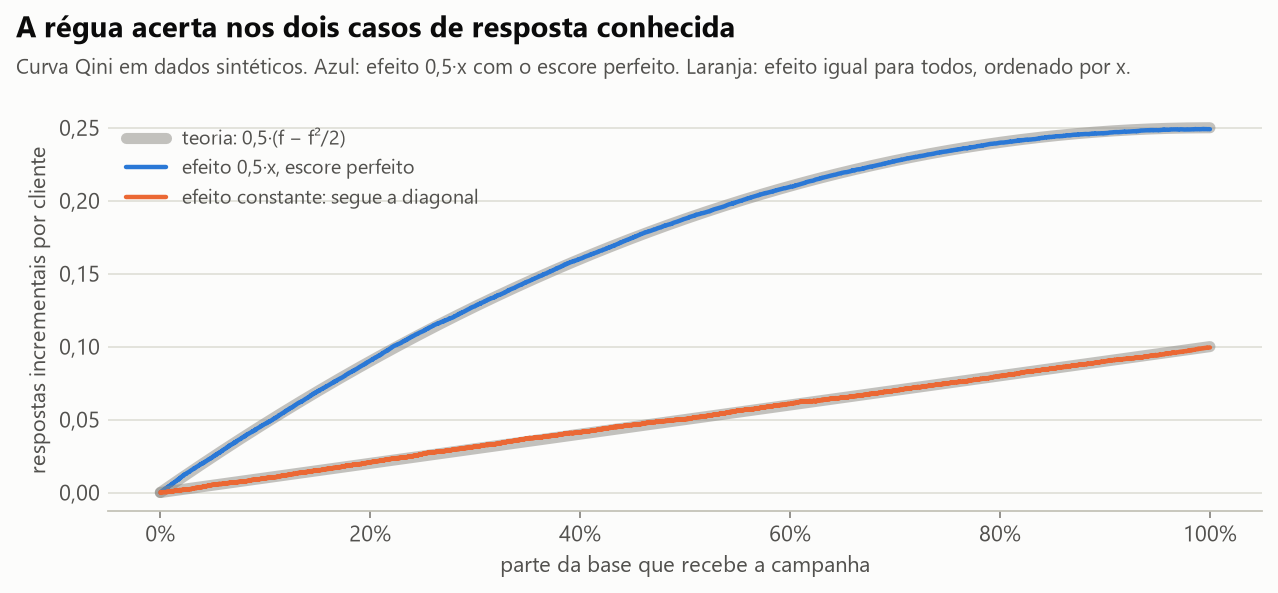

In [6]:
gerador = np.random.default_rng(0)
n = 200_000
x = gerador.uniform(0, 1, n)
t = gerador.integers(0, 2, n)

y_heterogeneo = (gerador.uniform(0, 1, n) < 0.1 + 0.5 * x * t).astype(int)        # efeito 0,5·x
y_constante = (gerador.uniform(0, 1, n) < 0.05 + 0.6 * x + 0.10 * t).astype(int)  # efeito 0,10 para todos; x só muda a taxa de base

print(f"Efeito 0,5·x, escore perfeito:  Qini = {curvas.coeficiente_qini(y_heterogeneo, t, x):.4f}   (teoria: {1 / 24:.4f})")
print(f"Efeito 0,5·x, escore invertido: Qini = {curvas.coeficiente_qini(y_heterogeneo, t, -x):.4f}  (teoria: {-1 / 24:.4f})")
print(f"Efeito constante, escore = x:   Qini = {curvas.coeficiente_qini(y_constante, t, x):.4f}   (teoria: 0)")

with plt.rc_context(ESTILO):
    fig, ax = nova_figura(
        "A régua acerta nos dois casos de resposta conhecida",
        "Curva Qini em dados sintéticos. Azul: efeito 0,5·x com o escore perfeito. Laranja: efeito igual para todos, ordenado por x.",
        altura=3.8,
    )
    f1, g1 = curvas.curva_qini(y_heterogeneo, t, x)
    f2, g2 = curvas.curva_qini(y_constante, t, x)
    ax.plot(f1, 0.5 * (f1 - f1**2 / 2), color=APAGADO, linewidth=5, alpha=0.5, label="teoria: 0,5·(f − f²/2)")
    ax.plot(f1, g1, color=AZUL, label="efeito 0,5·x, escore perfeito")
    ax.plot(f2, 0.10 * f2, color=APAGADO, linewidth=5, alpha=0.5)
    ax.plot(f2, g2, color=LARANJA, label="efeito constante: segue a diagonal")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v * 100:.0f}%"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:.2f}".replace(".", ",")))
    ax.set_xlabel("parte da base que recebe a campanha")
    ax.set_ylabel("respostas incrementais por cliente")
    ax.legend(loc="upper left", fontsize=9)
    plt.show()

O segundo caso é o coração do estudo: ali x prevê muito bem quem responde, e mesmo assim ordenar por x não rende
nada, porque o e-mail soma a mesma coisa para todo mundo. **Prever resposta e prever efeito são tarefas diferentes.**

## 4. Os modelos, ao vivo

Quatro jeitos de estimar o efeito por cliente, todos montados em `uplift_campanha/uplift.py` sobre classificadores
comuns:

- **dois modelos (T-learner):** um modelo de resposta com quem recebeu, outro com quem não recebeu; uplift = diferença;
- **transformação de classe:** um modelo só, com o alvo trocado (recebeu e respondeu, ou não recebeu e não respondeu);
- **modelo único com interações (S-learner):** atributos, tratamento e atributo × tratamento;
- **X-learner:** dois estágios, imputando o efeito de cada cliente com o modelo do outro grupo.

Linhas de base: o **modelo de resposta** (treinado só com quem recebeu; ordena por quem mais visita), a regra
"comprou mais recentemente" e a regra "já comprou a linha anunciada no e-mail".

A célula abaixo refaz, para o e-mail feminino, a separação treino/teste (metade e metade, estratificada por
tratamento e desfecho), treina tudo com regressão logística e mede o Qini em visita na metade de teste.

In [7]:
campanha = "E-mail feminino"
recorte = dados.recorte_da_campanha(tabela, campanha)
treino, teste = dados.separar_treino_teste(recorte, semente=analise.SEMENTE)
print(f"treino: {len(treino):,} clientes · teste: {len(teste):,} clientes".replace(",", "."))

modelos = uplift.ajustar_todos("logistica", dados.matriz(treino), treino["tratado"].to_numpy(), treino["visita"].to_numpy())
escores = {analise.chave(nome, "logistica"): modelo.prever_uplift(dados.matriz(teste)) for nome, modelo in modelos.items()}
escores |= analise.regras(teste, campanha)

y, t = teste["visita"].to_numpy(), teste["tratado"].to_numpy()
ao_vivo = pd.Series({nome: 1000 * curvas.coeficiente_qini(y, t, escore) for nome, escore in escores.items()})

# Conferência: o que sai aqui tem de ser o que está em reports/resultados.json (gravado com dez casas decimais).
do_arquivo = {linha["escore"]: 1000 * linha["qini"] for linha in resultados["campanhas"][campanha]["visita"]["metodos"]}
assert all(abs(ao_vivo[nome] - do_arquivo[nome]) < 1e-6 for nome in ao_vivo.index), "o notebook e o resultados.json divergiram"
print("Confere com reports/resultados.json.")

pd.DataFrame({"método": [analise.nome_do_escore(nome, campanha) for nome in ao_vivo.index], "Qini (visitas por mil clientes)": ao_vivo.to_numpy()}).round(2)

treino: 21.348 clientes · teste: 21.345 clientes


Confere com reports/resultados.json.


,método,Qini (visitas por mil clientes)
0,Dois modelos (T-learner) · regressão logística,9.120
1,Transformação de classe · regressão logística,9.340
2,Modelo único com interações (S-learner) · regr...,9.100
3,X-learner · regressão logística,8.690
4,Modelo de resposta · regressão logística,4.470
5,Regra: quem comprou mais recentemente,-1.450
6,Regra: quem já comprou a linha feminina,9.040


## 5. Resultado em visita, com incerteza

A tabela completa, das duas campanhas: Qini na metade de teste com intervalo de 95% por bootstrap (mil reamostras
dos clientes do teste) e a diferença pareada para o modelo de resposta. O método principal de cada campanha foi
escolhido por validação cruzada dentro do treino, sem olhar o teste.

In [8]:
def tabela_de_metodos(campanha: str, desfecho: str) -> pd.DataFrame:
    linhas = pd.DataFrame(resultados["campanhas"][campanha][desfecho]["metodos"]).set_index("nome")
    saida = 1000 * linhas[["qini", "qini_ic_inferior", "qini_ic_superior", "diferenca_para_a_base", "diferenca_ic_inferior", "diferenca_ic_superior"]]
    saida.columns = ["Qini", "IC 95% inf.", "IC 95% sup.", "dif. p/ resposta", "dif. IC inf.", "dif. IC sup."]
    return saida.round(2)


for campanha in dados.CAMPANHAS:
    bloco = resultados["campanhas"][campanha]
    print(f"{campanha} · principal (escolhido no treino): {bloco['principal']['nome']} · linha de base: {bloco['base']['nome']}")
    display(tabela_de_metodos(campanha, "visita"))

E-mail feminino · principal (escolhido no treino): Dois modelos (T-learner) · regressão logística · linha de base: Modelo de resposta · regressão logística


,Qini,IC 95% inf.,IC 95% sup.,dif. p/ resposta,dif. IC inf.,dif. IC sup.
nome,,,,,,
Dois modelos (T-learner) · regressão logística,9.120,6.380,11.750,4.640,1.920,7.350
Transformação de classe · regressão logística,9.340,6.730,11.840,4.860,2.410,7.260
Modelo único com interações (S-learner) · regressão logística,9.100,6.360,11.700,4.620,1.900,7.320
X-learner · regressão logística,8.690,6.210,11.120,4.210,1.390,7.030
Modelo de resposta · regressão logística,4.470,1.810,7.180,0.000,0.000,0.000
Dois modelos (T-learner) · LightGBM,6.010,3.170,8.590,1.540,-1.400,4.690
Transformação de classe · LightGBM,3.840,1.310,6.230,-0.640,-4.040,2.700
Modelo único com interações (S-learner) · LightGBM,8.600,5.930,11.180,4.120,1.530,6.720
X-learner · LightGBM,6.000,3.220,8.600,1.530,-1.300,4.580


E-mail masculino · principal (escolhido no treino): X-learner · regressão logística · linha de base: Modelo de resposta · regressão logística


,Qini,IC 95% inf.,IC 95% sup.,dif. p/ resposta,dif. IC inf.,dif. IC sup.
nome,,,,,,
Dois modelos (T-learner) · regressão logística,1.600,-1.260,4.270,-0.130,-1.800,1.550
Transformação de classe · regressão logística,1.700,-1.250,4.360,-0.030,-1.670,1.980
Modelo único com interações (S-learner) · regressão logística,1.720,-1.110,4.350,-0.010,-1.560,1.620
X-learner · regressão logística,1.500,-1.410,4.160,-0.230,-1.830,1.440
Modelo de resposta · regressão logística,1.730,-1.190,4.410,0.000,0.000,0.000
Dois modelos (T-learner) · LightGBM,-1.090,-4.080,1.790,-2.820,-5.420,0.110
Transformação de classe · LightGBM,-0.810,-3.820,1.760,-2.540,-5.760,0.780
Modelo único com interações (S-learner) · LightGBM,-0.350,-3.340,2.470,-2.080,-3.880,0.070
X-learner · LightGBM,-0.680,-3.710,2.200,-2.410,-4.900,0.150


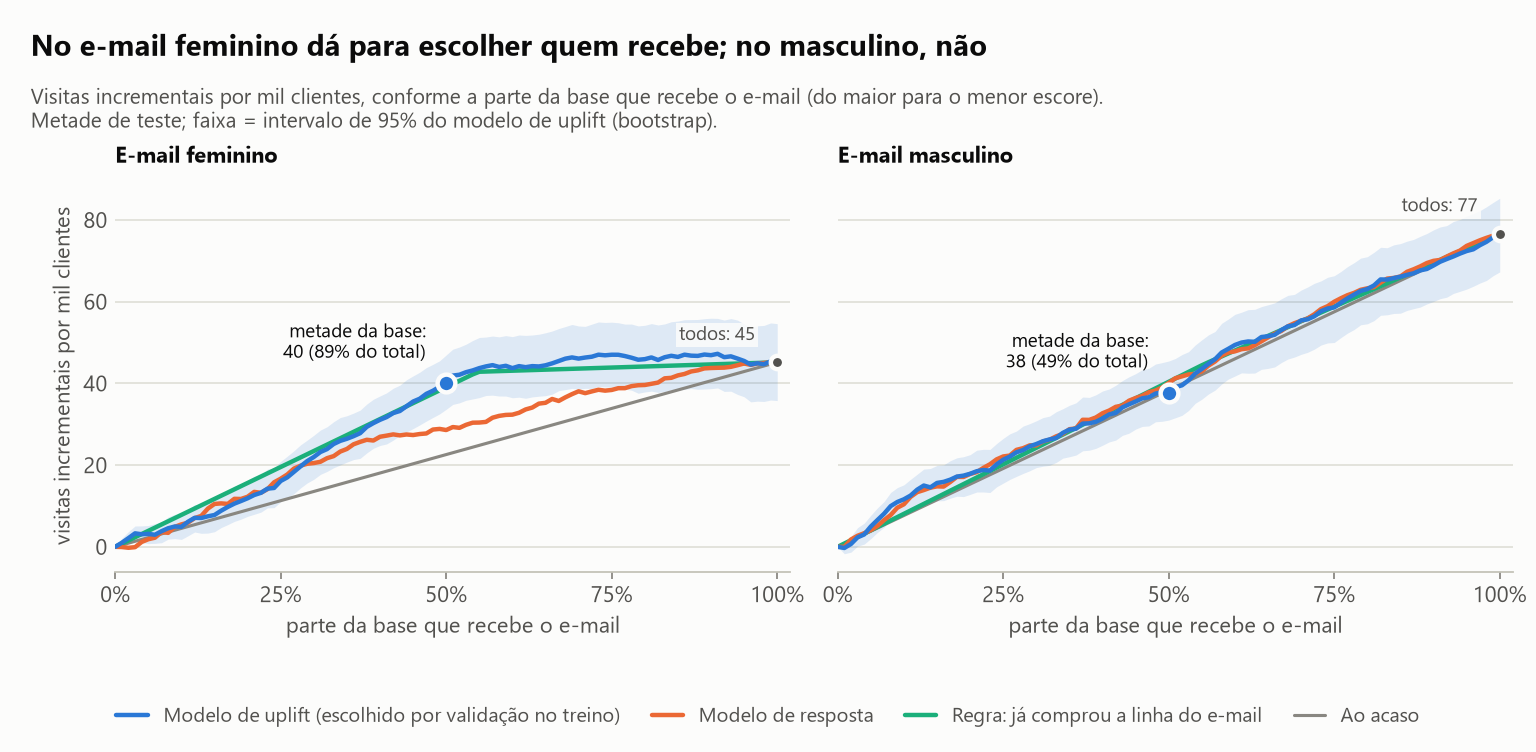

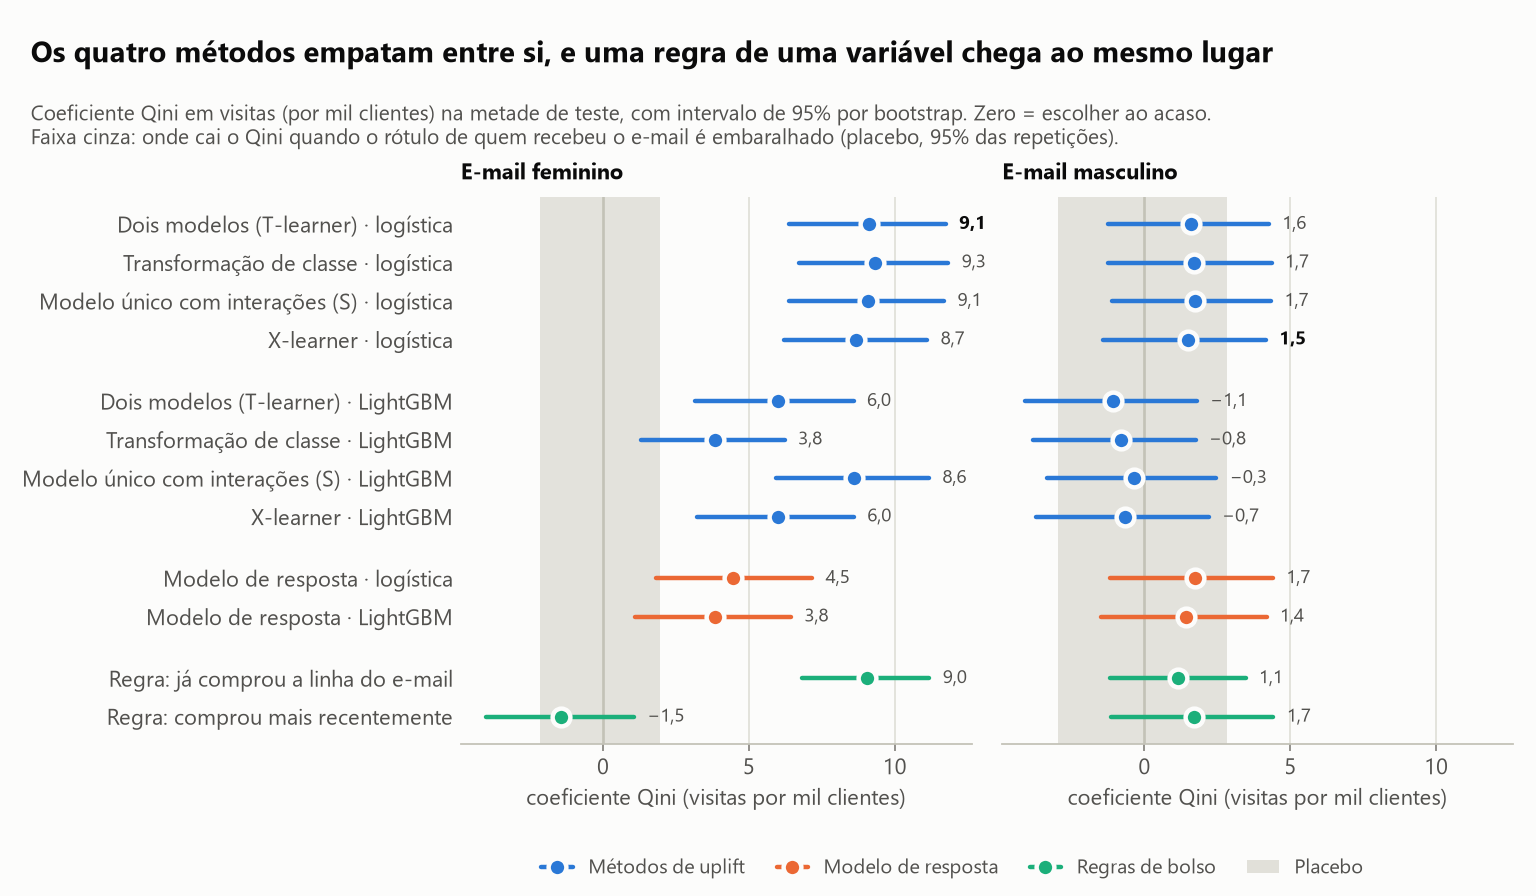

In [9]:
display(Image(filename="reports/figuras/qini_visita.png", width=900))
display(Image(filename="reports/figuras/comparacao_dos_metodos.png", width=900))

Três leituras:

1. **E-mail feminino:** o modelo de uplift tem cerca do dobro do Qini do modelo de resposta, e a diferença pareada
   não inclui o zero. Só que a regra de uma variável, "já comprou a linha feminina", chega ao mesmo lugar.
2. **E-mail masculino:** nenhum escore se distingue do acaso. O efeito é parecido em toda a base.
3. **Os quatro métodos empatam entre si** com regressão logística. Com LightGBM ficam iguais ou piores: com efeito
   pequeno e poucos atributos, o modelo flexível decora ruído.

A escolha do método principal, feita só com o treino:

In [10]:
for campanha in dados.CAMPANHAS:
    escolha = pd.DataFrame(resultados["campanhas"][campanha]["escolha_do_principal_por_validacao_cruzada_no_treino"]).set_index("nome")
    escolha[["qini_medio", "desvio_entre_dobras"]] *= 1000
    print(campanha)
    display(escolha[["qini_medio", "desvio_entre_dobras", "dobras_acima_do_acaso"]].round(2))

E-mail feminino


,qini_medio,desvio_entre_dobras,dobras_acima_do_acaso
nome,,,
Dois modelos (T-learner) · regressão logística,5.180,2.920,5
Modelo único com interações (S-learner) · regressão logística,5.180,2.950,5
X-learner · regressão logística,4.960,3.370,4
Transformação de classe · regressão logística,4.610,3.470,4
Modelo único com interações (S-learner) · LightGBM,3.690,4.220,4
X-learner · LightGBM,2.230,5.100,3
Dois modelos (T-learner) · LightGBM,1.680,5.290,3
Transformação de classe · LightGBM,1.470,4.070,3


E-mail masculino


,qini_medio,desvio_entre_dobras,dobras_acima_do_acaso
nome,,,
X-learner · regressão logística,4.960,1.910,5
Dois modelos (T-learner) · regressão logística,4.770,2.040,5
Modelo único com interações (S-learner) · regressão logística,4.660,2.140,5
Transformação de classe · regressão logística,4.130,2.020,5
Modelo único com interações (S-learner) · LightGBM,2.440,2.340,4
X-learner · LightGBM,0.410,2.360,3
Dois modelos (T-learner) · LightGBM,-0.050,2.600,3
Transformação de classe · LightGBM,-1.400,0.410,0


O desvio entre dobras é do tamanho da diferença entre os métodos da família logística: a ordem entre eles é, em
boa parte, sorteio. A escolha separa as famílias (logística à frente do LightGBM), não os métodos.

## 6. Valor de política: o que cada escolha entrega

Qini é uma área. A decisão de negócio é mais direta: se o e-mail for só para os X% de maior escore, quantas visitas
incrementais por mil clientes da base isso rende? Mandar ao acaso para X% rende X% do efeito médio; mandar para
todos rende o efeito médio.

In [11]:
def tabela_de_politica(campanha: str, desfecho: str) -> pd.DataFrame:
    linhas = pd.DataFrame(resultados["campanhas"][campanha][desfecho]["valor_da_politica"])
    linhas = linhas[linhas["fracao"] < 1]
    linhas["parte da base"] = (100 * linhas["fracao"]).round().astype(int).astype(str) + "%"
    saida = linhas.set_index(["parte da base", "nome"])[
        ["por_mil_clientes", "ic_inferior", "ic_superior", "parte_do_efeito_total", "acima_do_acaso", "acima_ic_inferior", "acima_ic_superior"]
    ]
    saida.columns = ["por mil clientes", "IC inf.", "IC sup.", "parte do efeito total", "acima do acaso", "acima IC inf.", "acima IC sup."]
    return saida.round(2)


todos = {c: 1000 * resultados["campanhas"][c]["visita"]["curva_qini"]["efeito_medio_no_teste"] for c in dados.CAMPANHAS}
print("Mandar para todos, em visitas incrementais por mil clientes:", {c: round(v, 1) for c, v in todos.items()})
display(tabela_de_politica("E-mail feminino", "visita"))
display(tabela_de_politica("E-mail masculino", "visita"))

Mandar para todos, em visitas incrementais por mil clientes: {'E-mail feminino': 45.2, 'E-mail masculino': 76.7}


por mil clientes  IC inf.  IC sup.  parte do efeito total  acima do acaso  acima IC inf.  acima IC sup.
parte da base nome                                                                                                                                                   
10%           Ao acaso                                                   4.520    3.580    5.460                  0.100           0.000          0.000          0.000
              Dois modelos (T-learner) · regressão logística             4.900    1.810    7.920                  0.110           0.380         -2.560          3.270
              Modelo de resposta · regressão logística                   5.350    1.620    8.900                  0.120           0.830         -2.600          4.280
              Regra: quem já comprou a linha feminina                    7.760    6.520    9.090                  0.170           3.250          2.450          4.020
              Regra: quem comprou mais recentemente                      5.820    3.110    8.640                  0.130           1.310         -1.070          3.730
20%           Ao acaso                                                   9.030    7.160   10.920                  0.200           0.000          0.000          0.000
              Dois modelos (T-learner) · regressão logística            11.860    7.490   16.270                  0.260           2.830         -0.890          6.820
              Modelo de resposta · regressão logística                  12.270    7.290   17.280                  0.270           3.240         -1.090          7.600
              Regra: quem já comprou a linha feminina                   15.530   13.040   18.190                  0.340           6.490          4.900          8.040
              Regra: quem comprou mais recentemente                     10.550    6.470   14.750                  0.230           1.520         -1.850          4.870
30%           Ao acaso                                                  13.550   10.740   16.390                  0.300           0.000          0.000          0.000
              Dois modelos (T-learner) · regressão logística            21.980   16.500   27.080                  0.490           8.430          4.320         12.570
              Modelo de resposta · regressão logística                  20.480   14.320   26.590                  0.450           6.930          2.150         11.570
              Regra: quem já comprou a linha feminina                   23.290   19.560   27.280                  0.520           9.740          7.350         12.060
              Regra: quem comprou mais recentemente                     13.860    8.450   18.910                  0.310           0.310         -3.780          4.310
50%           Ao acaso                                                  22.580   17.900   27.310                  0.500           0.000          0.000          0.000
              Dois modelos (T-learner) · regressão logística            40.090   33.460   46.930                  0.890          17.510         12.790         22.000
              Modelo de resposta · regressão logística                  28.550   20.730   35.620                  0.630           5.970          1.440         10.640
              Regra: quem já comprou a linha feminina                   38.820   32.600   45.470                  0.860          16.230         12.250         20.100
              Regra: quem comprou mais recentemente                     16.830    9.670   23.770                  0.370          -5.750         -9.910         -1.380
70%           Ao acaso                                                  31.610   25.060   38.240                  0.700           0.000          0.000          0.000
              Dois modelos (T-learner) · regressão logística            46.050   38.500   54.160                  1.020          14.430         10.490         18.390
              Modelo de resposta · regressão logística                  38.110

por mil clientes  IC inf.  IC sup.  parte do efeito total  acima do acaso  acima IC inf.  acima IC sup.
parte da base nome                                                                                                                                             
10%           Ao acaso                                             7.670    6.730    8.530                  0.100           0.000          0.000          0.000
              X-learner · regressão logística                     11.100    7.610   14.510                  0.140           3.430          0.170          6.640
              Modelo de resposta · regressão logística             9.820    6.260   13.600                  0.130           2.160         -1.270          5.850
              Regra: quem já comprou a linha masculina             8.070    6.750    9.330                  0.110           0.410         -0.430          1.240
              Regra: quem comprou mais recentemente               10.360    7.280   12.960                  0.140           2.690         -0.020          5.020
20%           Ao acaso                                            15.330   13.460   17.060                  0.200           0.000          0.000          0.000
              X-learner · regressão logística                     17.530   12.560   22.040                  0.230           2.200         -2.180          6.150
              Modelo de resposta · regressão logística            17.480   12.540   22.310                  0.230           2.140         -2.320          6.290
              Regra: quem já comprou a linha masculina            16.150   13.500   18.670                  0.210           0.810         -0.860          2.470
              Regra: quem comprou mais recentemente               19.500   15.050   23.790                  0.250           4.170          0.180          7.590
30%           Ao acaso                                            23.000   20.190   25.590                  0.300           0.000          0.000          0.000
              X-learner · regressão logística                     24.770   19.010   30.560                  0.320           1.770         -3.110          6.260
              Modelo de resposta · regressão logística            24.590   18.880   30.610                  0.320           1.590         -3.070          6.310
              Regra: quem já comprou a linha masculina            24.220   20.250   28.000                  0.320           1.220         -1.290          3.710
              Regra: quem comprou mais recentemente               27.200   21.650   32.410                  0.350           4.200         -0.220          8.320
50%           Ao acaso                                            38.340   33.640   42.660                  0.500           0.000          0.000          0.000
              X-learner · regressão logística                     37.740   30.790   44.880                  0.490          -0.590         -5.380          3.940
              Modelo de resposta · regressão logística            39.930   32.280   47.340                  0.520           1.590         -3.580          6.330
              Regra: quem já comprou a linha masculina            40.370   33.760   46.660                  0.530           2.040         -2.150          6.190
              Regra: quem comprou mais recentemente               38.570   31.320   45.610                  0.500           0.230         -4.720          4.920
70%           Ao acaso                                            53.670   47.100   59.720                  0.700           0.000          0.000          0.000
              X-learner · regressão logística                     55.710   47.330   63.280                  0.730           2.030         -2.230          5.990
              Modelo de resposta · regressão logística            55.190   47.050   63.280                  0.720           1.520         -2.550          5.210
              Regra: quem já comprou a linha masculina  

No e-mail feminino, metade da base escolhida pelo modelo de uplift entrega quase todo o efeito de mandar para
todos. Até 30% da base, o modelo de uplift e o de resposta escolhem igualmente bem; a diferença aparece da metade
em diante, quando o modelo de resposta continua atrás de quem visita muito e o de uplift já pegou quem responde ao
e-mail. A figura mostra por quê: o público do modelo de resposta já visitaria sem e-mail.

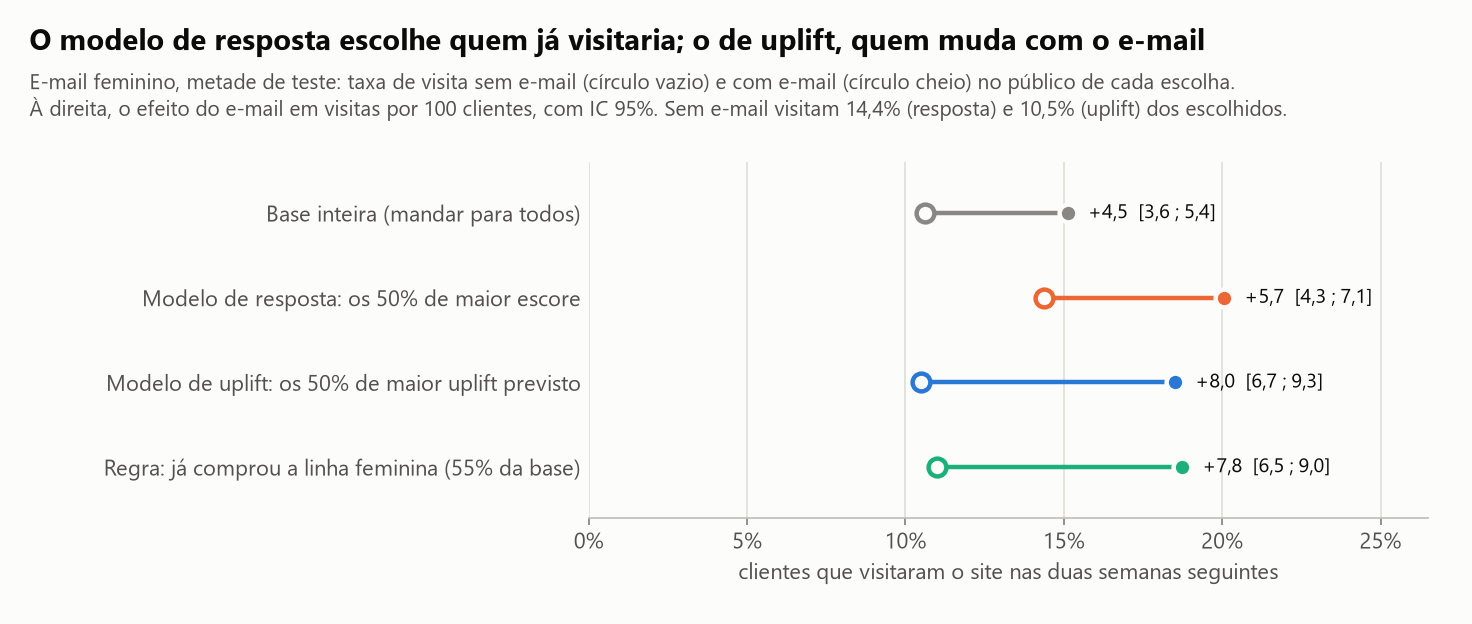

,parte_da_base,taxa_sem_email,taxa_com_email,uplift,uplift_ic_inferior,uplift_ic_superior,comprou_feminino,comprou_masculino,cliente_novo,recencia_media,historico_mediano
rotulo,,,,,,,,,,,
Base inteira (mandar para todos),1.000,0.106,0.151,0.045,0.036,0.054,0.548,0.551,0.506,5.739,160.330
Modelo de resposta: os 50% de maior escore,0.500,0.144,0.201,0.057,0.043,0.071,0.814,0.382,0.322,4.506,233.060
Modelo de uplift: os 50% de maior uplift previsto,0.500,0.105,0.185,0.080,0.067,0.093,1.000,0.143,0.518,5.565,183.205
Regra: já comprou a linha feminina (55% da base),0.548,0.110,0.187,0.078,0.065,0.090,1.000,0.180,0.516,5.641,186.425


In [12]:
display(Image(filename="reports/figuras/quem_cada_metodo_escolhe.png", width=860))
perfil = pd.DataFrame(resultados["campanhas"]["E-mail feminino"]["visita"]["quem_cada_escolha_alcanca"]["0.5"]).set_index("rotulo")
perfil[["parte_da_base", "taxa_sem_email", "taxa_com_email", "uplift", "uplift_ic_inferior", "uplift_ic_superior", "comprou_feminino", "comprou_masculino", "cliente_novo", "recencia_media", "historico_mediano"]].astype(float).round(3)

O uplift observado por décimo do teste, ordenado pelo uplift previsto, refeito ao vivo com o modelo da seção 4:

,taxa_sem_campanha,taxa_com_campanha,uplift,ic95_inferior,ic95_superior
faixa,,,,,
1,14.000,18.900,4.900,1.700,8.000
2,12.100,19.100,7.000,3.900,10.000
3,9.100,19.100,10.100,7.100,13.000
4,9.200,18.300,9.200,6.300,12.100
5,8.100,17.200,9.100,6.300,11.900
6,10.900,14.300,3.400,0.600,6.200
7,6.700,8.800,2.200,-0.100,4.500
8,8.600,8.500,-0.100,-2.500,2.300
9,10.100,11.100,1.000,-1.600,3.600


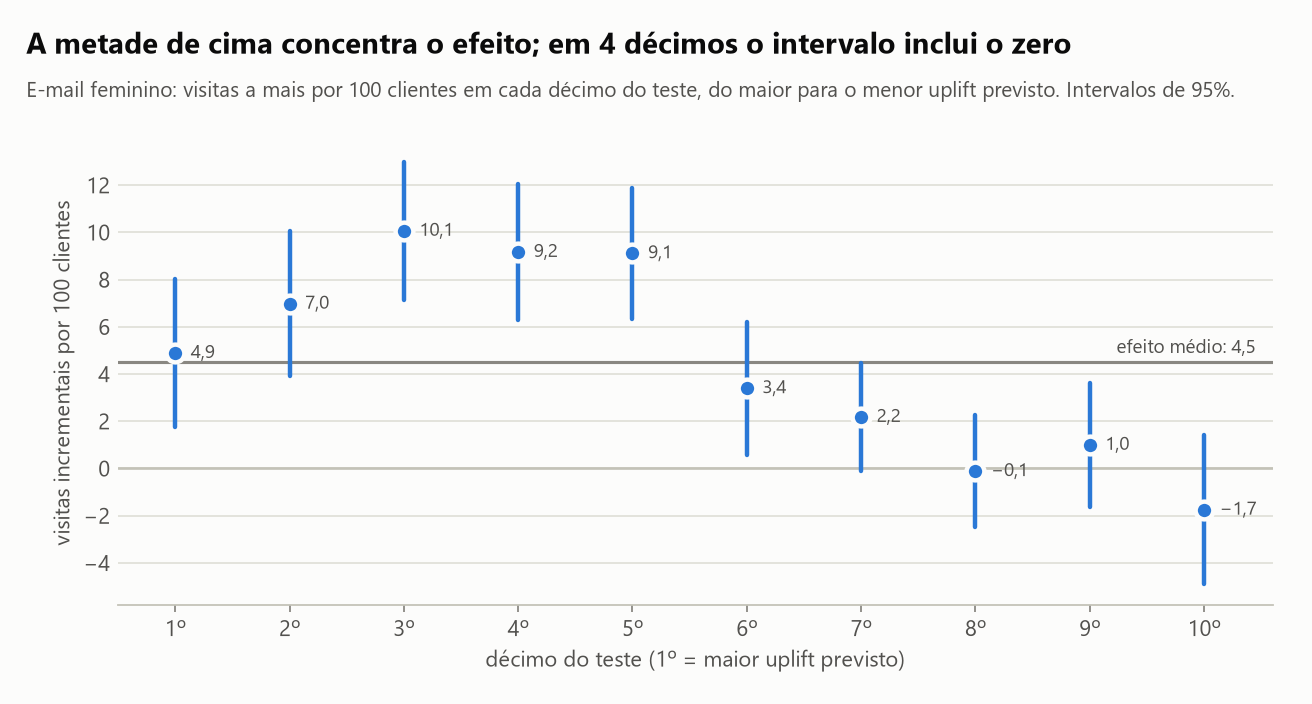

In [13]:
decis = curvas.uplift_por_faixa(y, t, escores[resultados["campanhas"]["E-mail feminino"]["principal"]["escore"]], faixas=10)
display((100 * decis[["taxa_sem_campanha", "taxa_com_campanha", "uplift", "ic95_inferior", "ic95_superior"]]).round(1))
display(Image(filename="reports/figuras/uplift_por_decil.png", width=820))

A ordem não é perfeita dentro da metade de cima (o primeiro décimo não é o de maior uplift), o que combina com a
leitura da regra: o que o modelo achou é, no essencial, uma variável binária. Quem já comprou a linha feminina
responde ao e-mail feminino; quem só comprou a masculina, não.

## 7. Robustez: placebo e outras separações

**Placebo.** Embaralhando quem "recebeu" o e-mail e refazendo tudo (separação, treino, avaliação), não existe efeito
para encontrar. Se o procedimento fabricasse ganho, o Qini continuaria positivo.

In [14]:
linhas = {}
for campanha in dados.CAMPANHAS:
    p = resultados["campanhas"][campanha]["visita"]["placebo"]
    linhas[campanha] = {
        "repetições": p["repeticoes"],
        "Qini observado": 1000 * p["qini_observado"],
        "Qini placebo, média": 1000 * p["qini_placebo_medio"],
        "placebo 2,5%": 1000 * p["qini_placebo_p2_5"],
        "placebo 97,5%": 1000 * p["qini_placebo_p97_5"],
        "placebo, máximo": 1000 * p["qini_placebo_maximo"],
        "p-valor": p["p_valor"],
    }
pd.DataFrame(linhas).T.round(3)

,repetições,Qini observado,"Qini placebo, média","placebo 2,5%","placebo 97,5%","placebo, máximo",p-valor
E-mail feminino,100.000,9.119,0.031,-2.176,1.960,3.944,0.010
E-mail masculino,100.000,1.496,-0.185,-2.978,2.829,3.909,0.099


**Outras separações.** O bootstrap do teste não enxerga a sorte de quem caiu no treino. Refazendo a separação com
20 sementes diferentes (família logística e regras):

In [15]:
for campanha in dados.CAMPANHAS:
    repeticoes = pd.DataFrame(resultados["campanhas"][campanha]["visita"]["repeticoes_da_separacao"]).set_index("nome")
    repeticoes[["qini_mediano", "qini_minimo", "qini_maximo"]] *= 1000
    print(campanha)
    display(repeticoes[["qini_mediano", "qini_minimo", "qini_maximo", "vezes_acima_do_acaso", "vezes_acima_da_base", "separacoes"]].round(2))

E-mail feminino


,qini_mediano,qini_minimo,qini_maximo,vezes_acima_do_acaso,vezes_acima_da_base,separacoes
nome,,,,,,
Dois modelos (T-learner) · regressão logística,8.050,6.080,8.970,20,20,20
Transformação de classe · regressão logística,7.670,5.170,9.160,20,19,20
Modelo único com interações (S-learner) · regressão logística,8.050,6.080,9.050,20,20,20
X-learner · regressão logística,7.620,6.510,8.630,20,20,20
Modelo de resposta · regressão logística,4.310,2.320,5.800,20,0,20
Regra: quem comprou mais recentemente,-0.370,-1.870,0.740,6,0,20
Regra: quem já comprou a linha feminina,7.740,6.530,8.600,20,20,20


E-mail masculino


,qini_mediano,qini_minimo,qini_maximo,vezes_acima_do_acaso,vezes_acima_da_base,separacoes
nome,,,,,,
Dois modelos (T-learner) · regressão logística,2.190,-0.840,3.500,19,0,20
Transformação de classe · regressão logística,2.130,-0.650,5.080,19,2,20
Modelo único com interações (S-learner) · regressão logística,2.230,-0.680,3.410,19,0,20
X-learner · regressão logística,1.830,-0.920,4.070,19,2,20
Modelo de resposta · regressão logística,3.760,2.920,5.040,20,0,20
Regra: quem comprou mais recentemente,1.900,0.100,3.260,20,0,20
Regra: quem já comprou a linha masculina,1.200,0.030,2.560,20,0,20


No e-mail feminino a ordem se mantém em praticamente todas as separações: uplift e regra acima do modelo de
resposta, regra da recência no chão. No masculino aparece um sinal pequeno que o teste único não tem tamanho para confirmar: o modelo
de resposta fica acima do acaso em todas as separações, e os métodos de uplift quase nunca o superam. As 20
separações reaproveitam os mesmos clientes, então não valem como 20 confirmações independentes.

## 8. E em compra?

E-mail feminino: na metade de teste, 94 compras entre os 10692 que receberam e 61 entre os 10653 que não receberam


,Qini,IC 95% inf.,IC 95% sup.,dif. p/ resposta,dif. IC inf.,dif. IC sup.
nome,,,,,,
Dois modelos (T-learner) · regressão logística,0.760,0.040,1.510,0.370,-0.190,0.980
Transformação de classe · regressão logística,0.120,-0.580,0.790,-0.270,-0.880,0.360
Modelo único com interações (S-learner) · regressão logística,0.920,0.220,1.660,0.540,0.040,1.050
X-learner · regressão logística,0.700,-0.010,1.400,0.320,-0.140,0.800
Modelo de resposta · regressão logística,0.380,-0.270,1.050,0.000,0.000,0.000
Dois modelos (T-learner) · LightGBM,0.280,-0.370,0.990,-0.110,-0.810,0.650
Transformação de classe · LightGBM,0.040,-0.640,0.740,-0.350,-1.220,0.510
Modelo único com interações (S-learner) · LightGBM,0.630,-0.030,1.320,0.240,-0.450,0.960
X-learner · LightGBM,0.290,-0.380,1.000,-0.090,-0.830,0.720


E-mail masculino: na metade de teste, 134 compras entre os 10654 que receberam e 61 entre os 10653 que não receberam


,Qini,IC 95% inf.,IC 95% sup.,dif. p/ resposta,dif. IC inf.,dif. IC sup.
nome,,,,,,
Dois modelos (T-learner) · regressão logística,0.240,-0.570,1.050,-0.260,-0.990,0.520
Transformação de classe · regressão logística,0.270,-0.430,1.040,-0.230,-1.220,0.780
Modelo único com interações (S-learner) · regressão logística,0.280,-0.540,1.090,-0.230,-0.910,0.500
X-learner · regressão logística,0.430,-0.350,1.260,-0.070,-0.700,0.600
Modelo de resposta · regressão logística,0.500,-0.210,1.310,0.000,0.000,0.000
Dois modelos (T-learner) · LightGBM,-0.040,-0.750,0.760,-0.540,-1.490,0.390
Transformação de classe · LightGBM,0.490,-0.250,1.220,-0.010,-1.010,1.080
Modelo único com interações (S-learner) · LightGBM,0.320,-0.350,1.120,-0.180,-1.070,0.650
X-learner · LightGBM,-0.020,-0.740,0.770,-0.520,-1.530,0.470


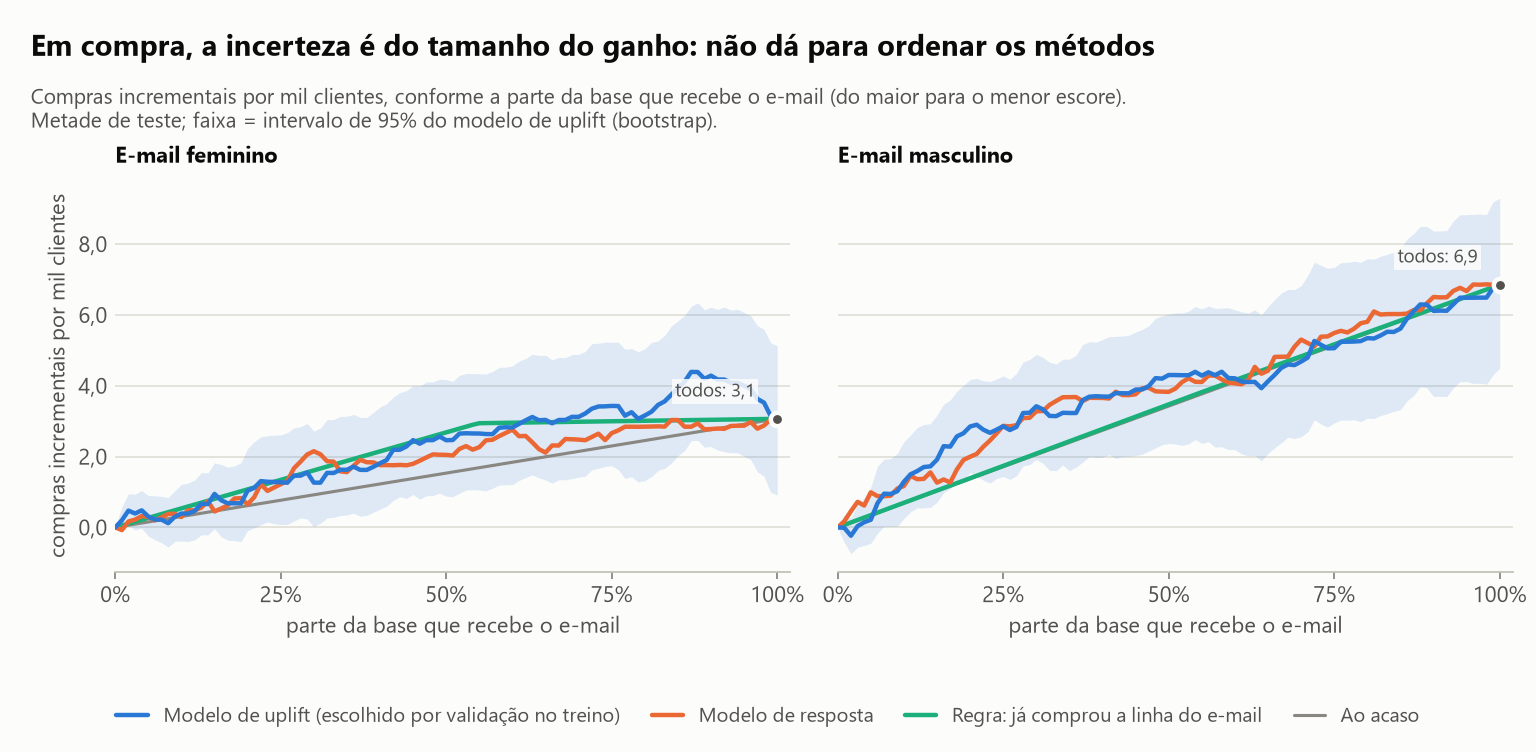

In [16]:
for campanha in dados.CAMPANHAS:
    separacao = resultados["campanhas"][campanha]["separacao"]
    print(
        f"{campanha}: na metade de teste, {separacao['compras_dos_tratados_no_teste']} compras entre os {separacao['tratados_no_teste']} que receberam "
        f"e {separacao['compras_dos_controles_no_teste']} entre os {separacao['controles_no_teste']} que não receberam"
    )
    display(tabela_de_metodos(campanha, "conversao"))
display(Image(filename="reports/figuras/qini_compra.png", width=900))

Em compra os intervalos têm o tamanho do próprio ganho. No e-mail feminino o Qini do modelo principal fica acima de
zero por pouco, e a diferença para o modelo de resposta inclui o zero; no masculino, quase tudo inclui o zero. Com
tão poucas compras por grupo na metade de teste (a contagem está acima de cada tabela), o experimento não tem
tamanho para ordenar métodos nesse desfecho.

## Conclusão

In [17]:
site = resultados["para_o_site"]
print(site["pergunta"]["pt"], "\n")
print(site["resultado"]["pt"], "\n")
print(site["detalhe"]["pt"])

Para quem mandar a campanha: para quem compra por causa dela, e não para quem compraria de qualquer jeito? 

No e-mail da linha feminina, mandar só para a metade da base com maior uplift previsto preserva 89% das visitas incrementais (IC 95%: 77% a 102%); com a mesma metade, o modelo de resposta comum preserva 63%. Mas a regra de uma variável “quem já comprou a linha feminina” empata com o modelo de uplift (Qini 9,0 contra 9,1 por mil clientes). 

No e-mail da linha masculina nenhum método se distingue do acaso (Qini do modelo de uplift: 1,5 por mil, IC 95% de −1,4 a 4,2): o efeito é parecido em toda a base e o certo é mandar para todos. Em compra, o efeito médio é de 0,3 a 0,7 ponto percentual e o experimento não tem tamanho para separar os métodos.


O que levar para a operação:

- **Modelo de uplift só se paga onde o efeito varia.** Antes de modelar, vale medir se há heterogeneidade; no
  e-mail masculino não havia o que escolher.
- **Compare com a regra que o time de CRM já usaria.** Aqui, "mandar o e-mail da linha feminina para quem já
  comprou a linha feminina" empata com quatro métodos de inferência causal.
- **Modelo de resposta não é modelo de efeito.** Ele acerta quem visita, e boa parte desse público visitaria de
  qualquer jeito.
- **Sem grupo de controle sorteado, nada disto é mensurável.** O que permite a conta é guardar, em toda campanha,
  uma fatia da base sem receber.